# <center> Проект КЭМ: ML - классификация клиентов банка

## Постановка задачи

Некий банк предоставил данные о своей последней маркетинговой кампании: задачей было привлечь клиентов для открытия депозита. Необходимо проанализировать эти данные, 

выявить закономерности и найти решающие факторы, повлиявшие на то, что клиент вложил деньги именно в этот банк. Если мы сможем это сделать, то поднимем доходы банка

 и поможем понять целевую аудиторию, которую необходимо привлекать путём рекламы и различных предложений.

`Бизнес-задача`: определить характеристики, по которым можно выявить клиентов, более склонных к открытию депозита в банке, и за счёт этого повысить результативность маркетинговой кампании.

`Техническая задача специалиста Data Science`: построить модель МL, которая на основе предложенных характеристик клиента будет предсказывать, воспользуется он предложением об открытии

депозита или нет.

`Основные цели:`

- Исследовать данные.

- Выявить характерные черты для потенциальных клиентов, чтобы чётко очертить целевую аудиторию и увеличить прибыль банка.

- Построить прогностическую модель и оценить её качество.

Этапы проекта:

1.	Первичная обработка данных (обработка пропусков и выбросов в данных).

2.	Разведывательный анализ данных (EDA). Необходимо будет исследовать данные, нащупать первые закономерности и выдвинуть гипотезы.

3.	Отбор и преобразование признаков. Перекодировка и преобразование данных таким образом, чтобы их можно было использовать при решении задачи классификации.

4.	Решение задачи классификации: логистическая регрессия и решающие деревья. Построение прогностических моделей и оценка их качества. Подбор оптимальных параметров моделей

для наилучшего результата конкретного алгоритма.

5.	Решение задачи классификации: ансамбли моделей и построение прогноза.

6. Выбор  модели, обеспечиваюшей наиболее качественные прогнозы, и определение её оптимальных параметров. 

Загружаем необходимые для работы библиотеки:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from  sklearn.ensemble import IsolationForest
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing  import LabelEncoder
from sklearn import linear_model 
from sklearn import tree 
from sklearn import ensemble 
from sklearn import metrics 
from sklearn import preprocessing 
from sklearn.model_selection import train_test_split 
from sklearn.feature_selection import SelectKBest, f_classif

## <center> Часть 1. Знакомство с данными, обработка пропусков и выбросов

### Задание 1

In [2]:
# Загружаем и выводим первичные данные
df = pd.read_csv('data/bank_fin.csv', sep = ';')
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,"2 343,00 $",yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,"45,00 $",no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,"1 270,00 $",yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,"2 476,00 $",yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,"184,00 $",no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,"1,00 $",yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,"733,00 $",no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,"29,00 $",no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0 $,no,yes,cellular,8,may,9,2,172,5,failure,no


        Сведения по данным:

**Данные о клиентах банка**:

- `age` (возраст);

- `job` (сфера занятости);

- `marital` (семейное положение);

- `education` (уровень образования);

- `default` (имеется ли просроченный кредит);

- `housing` (имеется ли кредит на жильё);

- `loan` (имеется ли кредит на личные нужды);

- `balance` (баланс).

**Данные, связанные с последним контактом в контексте текущей маркетинговой кампании**:

- `contact` (тип контакта с клиентом);

- `month` (месяц, в котором был последний контакт);

- `day` (день, в который был последний контакт);

- `duration` (продолжительность контакта в секундах).

**Прочие признаки**:

- `campaign` (количество контактов с этим клиентом в течение текущей кампании);

- `pdays` (количество пропущенных дней с момента последней маркетинговой кампании до контакта в текущей кампании);

- `previous` (количество контактов до текущей кампании)

- `poutcome` (результат прошлой маркетинговой кампании).

### Целевой признак:

- `deposit` - переменная, которая определяет, согласится ли клиент открыть депозит в банке.


In [3]:
# выведем общую информацию по датасету
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11137 non-null  object
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(6), object(11)
memory usage: 1.4+ MB


In [4]:
# исследуйте данные на предмет пропусков. Где есть пропущенные значения? Сколько их?
# ваш код
df['balance'].isna().sum()

np.int64(25)

In [5]:
# исследуйте данные на предмет пропусков. Где есть пропущенные значения? Сколько их?
# ваш код

# Количество пропусков для всех признаков
missing_counts = df.isna().sum()
print(missing_counts)

age           0
job           0
marital       0
education     0
default       0
balance      25
housing       0
loan          0
contact       0
day           0
month         0
duration      0
campaign      0
pdays         0
previous      0
poutcome      0
deposit       0
dtype: int64


### Задание 2

In [6]:
# есть ли в признаке job пропущенные значения? Возможно, они обозначены каким-то специальным словом?
# ваш код
df['job'].unique()

array(['admin.', 'technician', 'services', 'management', 'retired',
       'blue-collar', 'unemployed', 'entrepreneur', 'housemaid',
       'unknown', 'self-employed', 'student'], dtype=object)

In [7]:
df['education'].unique()

array(['secondary', 'tertiary', 'primary', 'unknown'], dtype=object)

In [8]:
df['education'].value_counts(dropna=False)

education
secondary    5476
tertiary     3689
primary      1500
unknown       497
Name: count, dtype: int64

In [9]:
df['job'].value_counts(dropna=False)

job
management       2566
blue-collar      1944
technician       1823
admin.           1334
services          923
retired           778
self-employed     405
student           360
unemployed        357
entrepreneur      328
housemaid         274
unknown            70
Name: count, dtype: int64

В признаках *job* и *education* пропущенные значения обозначены словом *unknown*. И их достаточно много. Запомним это.

In [10]:
# Копируем первичные данные и инициализируем переменную для рабочего датасета
data = df.copy()

Обработка проппусков в данных

### Задание 3

In [11]:
# преобразуйте признак balance таким образом, чтобы он корректно считывался, как вещественное число (float)

def clean_balance(x):
    if isinstance(x, str):
        # убираем символы валюты, пробелы
        x = x.replace('€', '').replace('$', '').replace(',', '.').replace(' ', '')
    return x

data['balance_clean'] = data['balance'].apply(clean_balance)
data['balance'] = pd.to_numeric(data['balance_clean'], errors='coerce')
# если временная колонка больше не нужна:
data = data.drop(columns=['balance_clean'])

In [12]:
# Вычислите среднее значение по преобразованному в корректный вид признаку balance
data['balance'].mean()

np.float64(1529.1290293615875)

### Задание 4

In [13]:
# обработайте пропуски в признаки balance , заменив их на медианные значения по данному признаку
# ваш код

# Вычислим медиану только по непустым значениям
median_val = data['balance'].median()

# Заполним пропуски медианой
data['balance'] = data['balance'].fillna(median_val)

# Проверка
print(f"Медиана balance: {median_val}")
print(f"Пропусков после заполнения: {data['balance'].isna().sum()}")


Медиана balance: 550.0
Пропусков после заполнения: 0


In [14]:
# Смотрим среднее значение после обработки пропусков медианой
data['balance'].mean()

np.float64(1526.9360329690019)

### Задание 5

In [15]:
# обработайте пропуски в категориальных признаках: job и education, заменив их на модальные значения
# ваш код

cols = ['job', 'education']

for col in cols:
    data[col] = data[col].astype(str).str.strip().str.lower()
# Заменяем значения 'unknown' на nan
data.loc[data['job'] == 'unknown', 'job'] = np.nan
data.loc[data['education'] == 'unknown', 'education'] = np.nan

# Заполняем пропуски модальным значением
for col in cols:
    mode_val = data[col].mode()[0]  
    data[col] = data[col].fillna(mode_val)

Рассчитаем средний баланс для клиентов с самой популярной работой и самым популярным уровнем образования (т. е. для тех, у кого одновременно самая популярная работа и самое популярное образование) после замены пропусков 

In [16]:
# Смотрим самые популярные работы и образование
top_job = data['job'].mode()[0]
top_education = data['education'].mode()[0]

print(f"Самая популярная работа: {top_job}")
print(f"Самое популярное образование: {top_education}")


Самая популярная работа: management
Самое популярное образование: secondary


In [17]:
# Фильтруем клиентов, у которых одновременно и та работа, и то образование
mask = (data['job'] == top_job) & (data['education'] == top_education)
filtered = data[mask]

print(f"Количество таких клиентов: {len(filtered)}")

Количество таких клиентов: 376


In [18]:
# Считаем средний баланс
avg_balance = filtered['balance'].mean()

print(f"Средний баланс: {avg_balance:.2f}")

Средний баланс: 1598.88


 ### Задание 6 Удаление выбросов по методу Тьюки

In [19]:
# удалите все выбросы для признака balance
# ваш код

Q1 = data['balance'].quantile(0.25)
Q3 = data['balance'].quantile(0.75)

IQR = Q3 - Q1

# Границы по Тьюки
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1}")
print(f"Q3: {Q3}")
print(f"IQR: {IQR}")
print(f"Нижняя граница: {lower_bound}")
print(f"Верхняя граница: {upper_bound}")

Q1: 123.0
Q3: 1699.0
IQR: 1576.0
Нижняя граница: -2241.0
Верхняя граница: 4063.0


In [20]:
# Удаление выбросов
mask = (data['balance'] >= lower_bound) & (data['balance'] <= upper_bound)
data_clean = data[mask].copy()

In [21]:
# Смотрим очищенный датасет
data_clean

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476.0,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184.0,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1.0,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733.0,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29.0,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0.0,no,yes,cellular,8,may,9,2,172,5,failure,no


По сравнению с исходным датасет уменьшился на 1056 строк (около 10 %)

## <center> Часть 2:  Разведывательный анализ (`EDA`)


### Начнём с описательных статистик для количественных переменных.

Рассчитать их и продумать подробную интерпретацию.

Описать данные, которые у нас есть, увидеть первые зависимости.

Рассмотреть минимальные и максимальные значения.

Посмотреть на меры разброса и оценить, насколько данные вариативны.

Сравнив меры центральной тенденции, сделать выводы о том, есть ли аномальные значения с меньшей или большей стороны.

Дополните выводы визуализациями. Вспомнить, какие диаграммы могут помочь в иллюстрации распределений количественных данных.

### Задание 1 Вычисление частот для открывших депозит и для тех, кто его не открыл с визуализацией

Частоты по признаку 'deposit':
deposit
no     5424
yes    4681
Name: count, dtype: int64

Относительные частоты (доли):
deposit
no     0.536764
yes    0.463236
Name: proportion, dtype: float64


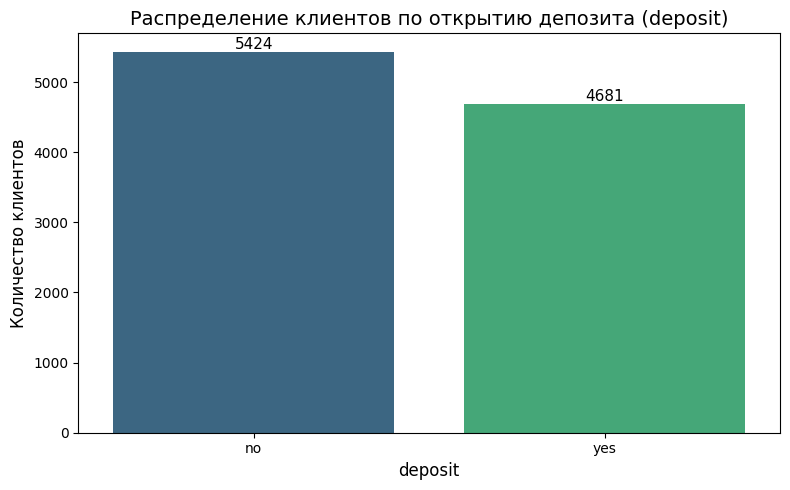

In [22]:
# изучите соотношение классов в ваших данных на предмет несбалансированности, проиллюстрируйте результат
# ваш код

# Частоты по признаку deposit
freq = data_clean['deposit'].value_counts().sort_index() 

print("Частоты по признаку 'deposit':")
print(freq)

# Относительные частоты (доли)
rel_freq = data_clean['deposit'].value_counts(normalize=True).sort_index()
print("\nОтносительные частоты (доли):")
print(rel_freq)

# Визуализация — столбчатая диаграмма
plt.figure(figsize=(8, 5))
sns.barplot(x=freq.index, y=freq.values, palette='viridis')

plt.title('Распределение клиентов по открытию депозита (deposit)', fontsize=14)
plt.xlabel('deposit', fontsize=12)
plt.ylabel('Количество клиентов', fontsize=12)

# Подписи значений на столбцах
for i, v in enumerate(freq.values):
    plt.text(i, v + 10, str(v), ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

`Вывод`: картина баланса классов такова - примерно 53.7 % «no» и 46.3 % «yes» — класс «yes» чуть меньше, но дисбаланс не экстремальный, классы достаточно сбалансированы

### Задания 2 и 3

In [23]:
#рассчитайте описательные статистики для количественных переменных, проинтерпретируйте результат
#ваш код
print(data_clean.describe())

# максимальный возраст клиента банка
print(data_clean['age'].max())

# минимальная и максимальная продолжительность разговора с клиентом банка исекундах
print(data_clean['duration'].min(), data_clean['duration'].max())

                age       balance           day      duration      campaign  \
count  10105.000000  10105.000000  10105.000000  10105.000000  10105.000000   
mean      40.895497    807.653538     15.590302    368.742603      2.517170   
std       11.734931    994.151966      8.441510    346.651524      2.707159   
min       18.000000  -2049.000000      1.000000      2.000000      1.000000   
25%       32.000000     95.000000      8.000000    137.000000      1.000000   
50%       38.000000    445.000000     15.000000    252.000000      2.000000   
75%       48.000000   1227.000000     22.000000    490.000000      3.000000   
max       95.000000   4063.000000     31.000000   3881.000000     43.000000   

              pdays      previous  
count  10105.000000  10105.000000  
mean      51.319644      0.816230  
std      109.644179      2.243795  
min       -1.000000      0.000000  
25%       -1.000000      0.000000  
50%       -1.000000      0.000000  
75%        2.000000      1.000000  


*balance*: сильный перекос и выбросы. Среднее (807.65) почти вдвое больше медианы (445), а максимум — 4063 при минимуме −2049. Это классическая картина с тяжёлыми хвостами.

*duration*: очень длинный правый хвост. Медиана 252, среднее 368.7, максимум 3881 — есть экстремальные значения. 

*previous* тоже перекошен. Медиана 0, среднее 0.82, максимум 58 — есть редкие клиенты с большим числом прошлых контактов.

### Рассмотрим описательные статистики для категориальных переменных.

Извлечь максимум информации из тех показателей, которые можно получить. 

Сколько всего сфер занятости представлено среди клиентов банка? В каждый ли месяц проходила маркетинговая кампания? Какое семейное положение встречается чаще всего? А образование? и т.д. и т.п.

Дать достаточно подробную интерпретацию. Для лучшей наглядности добавить визуализации по каждой категориальной переменной.

`Примечание`. Вопросы, приведённые выше, — это лишь пример того, что можно рассмотреть.

### Задания 4 и 5

In [24]:
#рассчитайте описательные статистики для категориальных переменных, проинтерпретируйте результат
#ваш код

# Сколько было месяцев, в которых проводилась маркетинговая кампания?
data_clean['month'].unique()
# Сколько сфер занятости представлено среди клиентов банка?
data_clean['job'].unique()
# семейное положение
data_clean['marital'].unique()
# уровни образования
data_clean['education'].unique()

array(['secondary', 'tertiary', 'primary'], dtype=object)

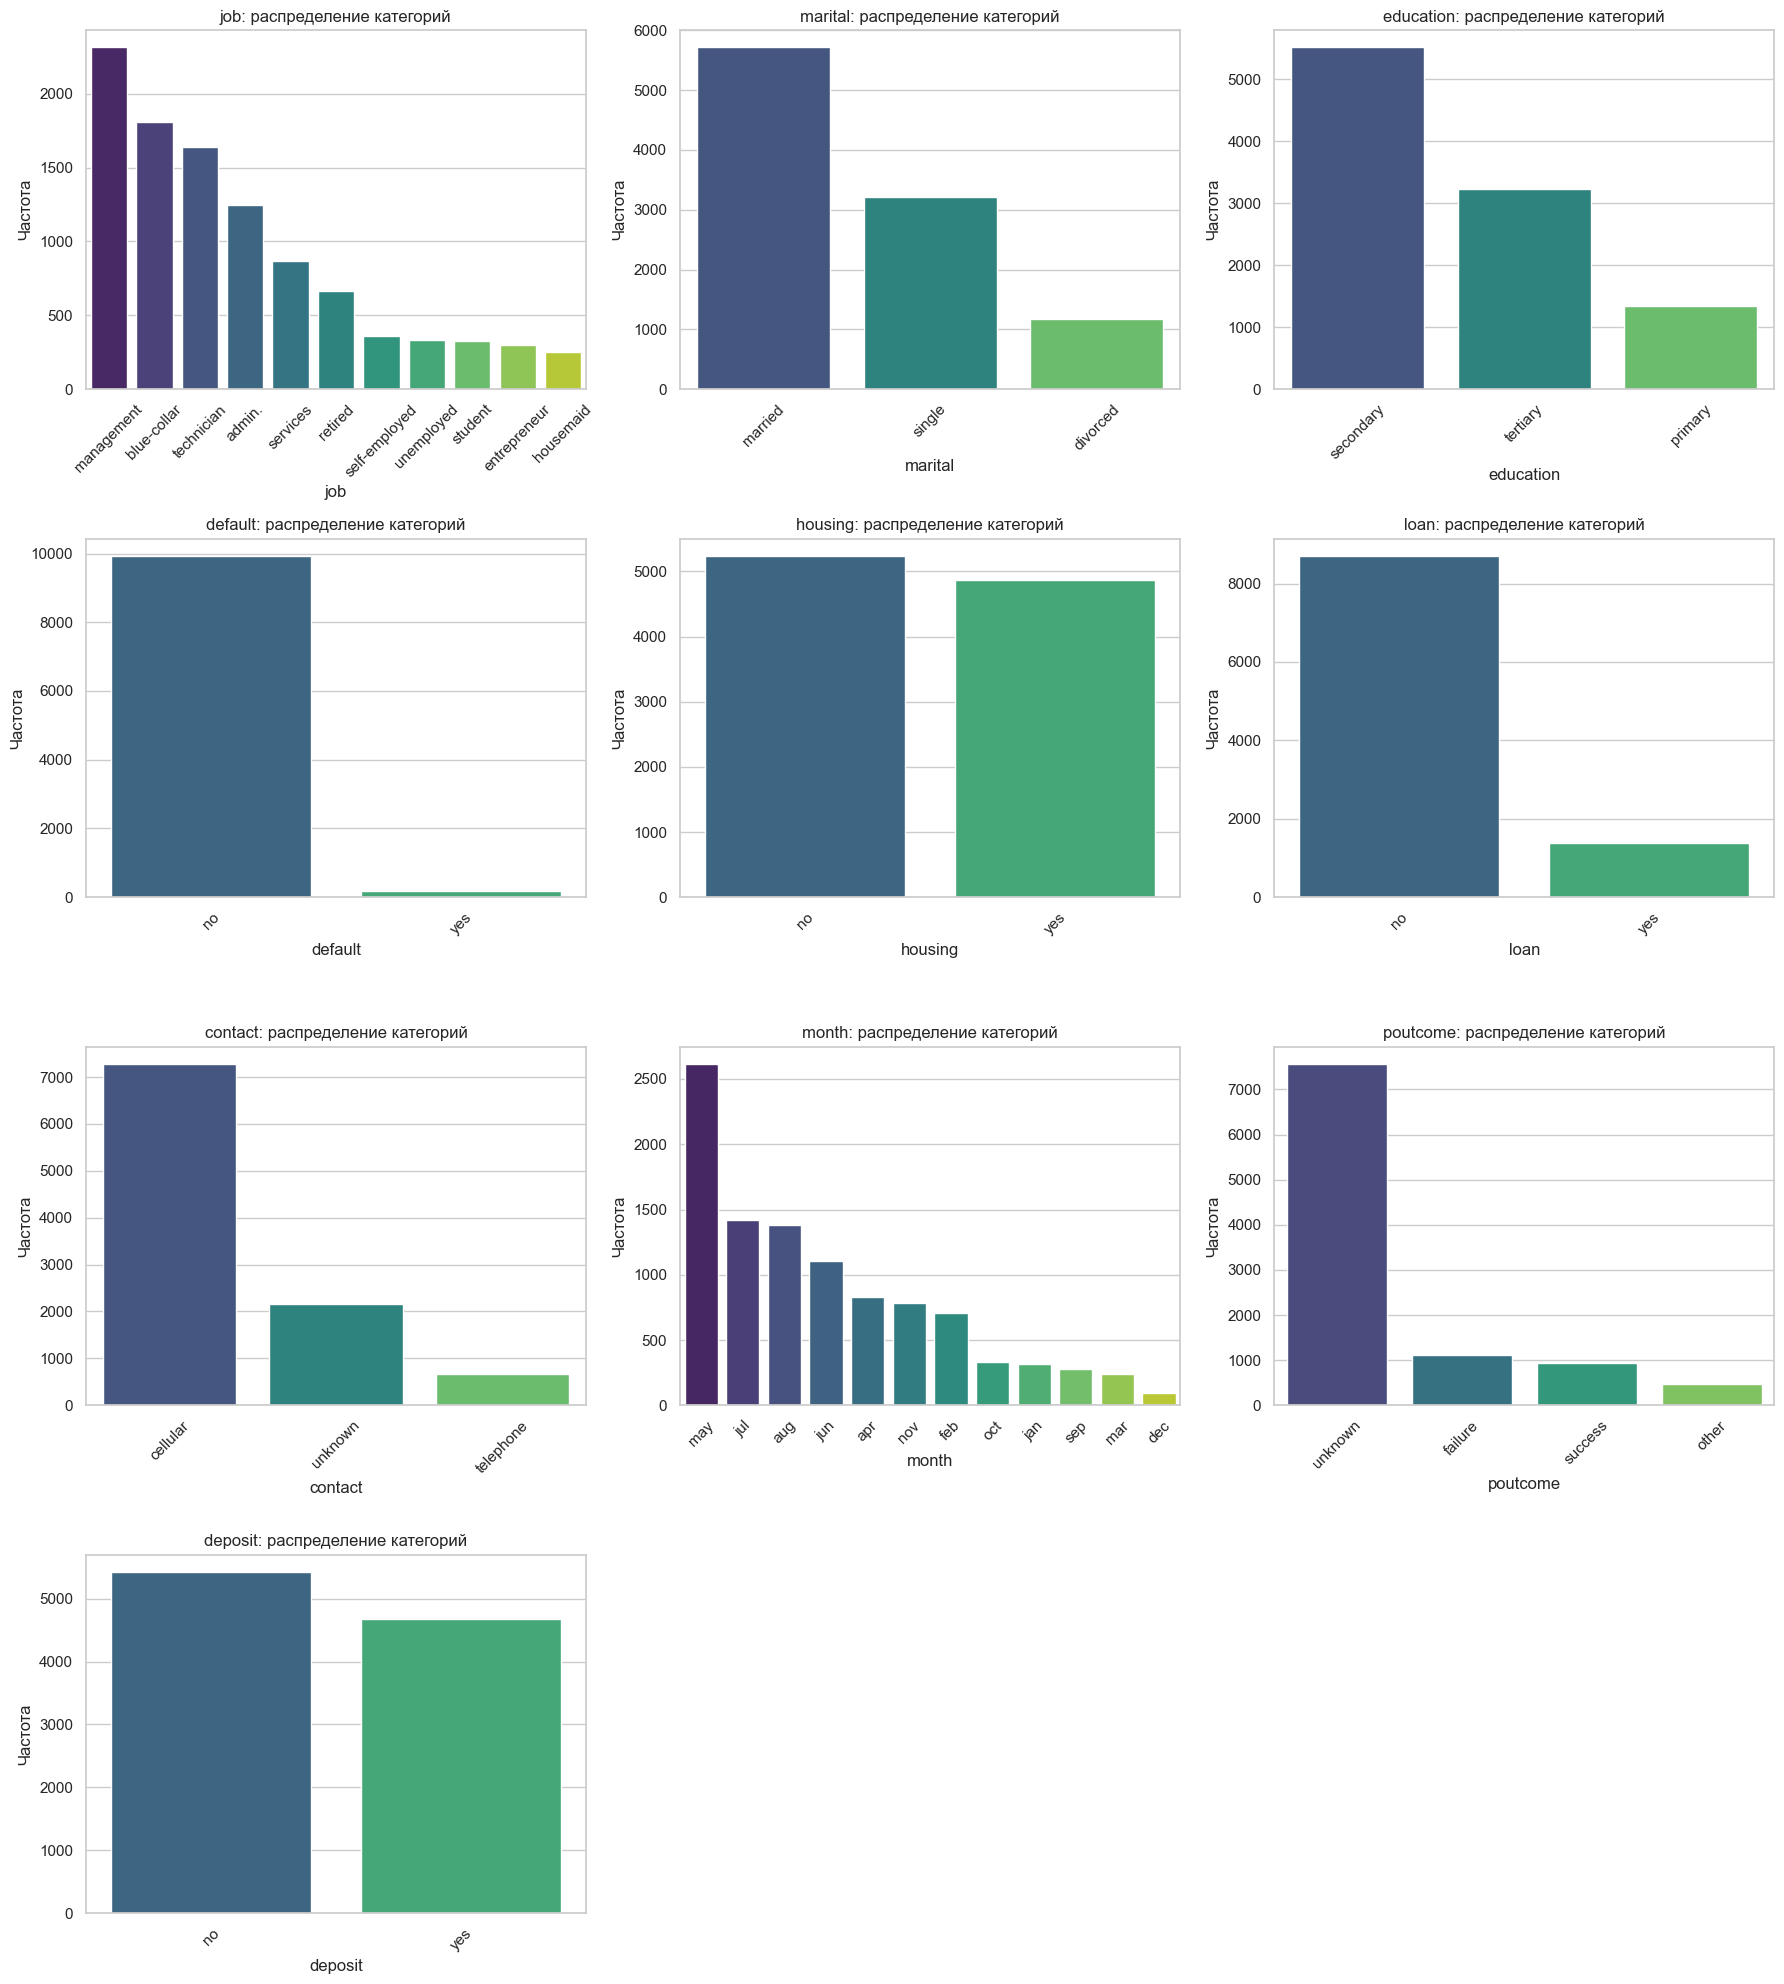

In [25]:
# строим визуализации, иллюстрирующие результаты

sns.set(style="whitegrid")

# выбираем только категориальные колонки
cat_cols = data_clean.select_dtypes(include=["object", "category"]).columns

n_cols = 3
n_rows = (len(cat_cols) + n_cols - 1) // n_cols

plt.figure(figsize=(18, 5 * n_rows))

for i, col in enumerate(cat_cols, 1):
    plt.subplot(n_rows, n_cols, i)
    counts = data_clean[col].value_counts(dropna=False)  # dropna=False покажет пропуски как отдельную категорию
    sns.barplot(x=counts.index, y=counts.values, palette="viridis")
    plt.xticks(rotation=45)
    plt.title(f"{col}: распределение категорий")
    plt.xlabel(col)
    plt.ylabel("Частота")
    plt.tight_layout()

plt.show()

Теперь узнаем, есть ли разница в результатах текущей маркетинговой кампании и предыдущей. Возможно, люди, которые уже однажды согласились на предложение банка, более склонны принять его вновь.

Узнаем, для какого статуса предыдущей маркетинговой кампании успех в текущей превалирует над количеством неудач.

### Задание 6

In [26]:
# Узнайте, для какого статуса предыдущей маркетинговой кампании успех в текущей превалирует над количеством неудач.
# ваш код

poutcome_counts = data_clean['poutcome'].value_counts(dropna=False)
print(poutcome_counts)

poutcome
unknown    7570
failure    1109
success     945
other       481
Name: count, dtype: int64


### Задание 7

Рассчитать, в каком месяце самый большой процент неудач при взаимодействии в текущей маркетинговой кампании. Возможно, этот месяц не является подходящим для проведения подобных акций. 

In [27]:
# узнайте, в каком месяце чаще всего отказывались от предложения открыть депозит
# ваш код

months = sorted(data_clean['month'].unique())
results = []

for m in months:
    # Подмножество данных по месяцу
    subset = data_clean[data_clean['month'] == m]
    
    # Общее количество принятых решений (не пропуски)
    total = subset['deposit'].notna().sum()
    
    if total == 0:
        ratio = None  # или 0, или np.nan — на выбор
        results.append({'month': m, 'total_decisions': total, 'rejections': 0, 'ratio': ratio})
        continue
    
    # Количество отказов (предполагаем, что отказ = 'no')
    rejections = (subset['deposit'] == 'no').sum()
    
    # Отношение отказов к общему количеству решений
    ratio = rejections / total
    
    results.append({
        'month': m,
        'total_decisions': total,
        'rejections': rejections,
        'ratio': ratio
    })

result_df = pd.DataFrame(results)
print(result_df)


   month  total_decisions  rejections     ratio
0    apr              830         317  0.381928
1    aug             1385         775  0.559567
2    dec               93           9  0.096774
3    feb              709         323  0.455571
4    jan              319         194  0.608150
5    jul             1418         836  0.589563
6    jun             1104         606  0.548913
7    mar              237          24  0.101266
8    may             2617        1776  0.678640
9    nov              780         456  0.584615
10   oct              335          62  0.185075
11   sep              278          46  0.165468


Чаще всего отказывались от предложения открыть депозит в мае

`Далее`. 

Посмотрим, люди какого возраста чаще открывают депозиты, а какого — реже. Так как возрастной разброс достаточно большой, визуализация для всех возрастов или нахождение статистики для каждого возраста не будет содержательным. 

В аналитике принято разделять людей по возрастным подгруппам и делать выводы уже по ним. Создадим новую переменную, в которой будет находиться индикатор принадлежности к одной из следующих категорий:

'<30'; '30-40'; '40-50'; '50-60'; '60+'.

Построим  диаграмму, которая сможет наилучшим образом отобразить различия в количестве открытых/не открытых депозитов для каждой возрастной группы.

### Задание 8

In [28]:
# создайте возрастные группы и определите, в каких группах более склонны открывать депозит, чем отказываться от предложения

def assign_age_group(age):
    if pd.isna(age):
        return 'Unknown'
    if age < 30:
        return '<30'
    elif 30 <= age < 40:
        return '30-40'
    elif 40 <= age < 50:
        return '40-50'
    elif 50 <= age < 60:
        return '50-60'
    else:
        return '60+'

data_clean['age_group'] = data_clean['age'].apply(assign_age_group)

Text(0.5, 1.0, 'Количество открытых и не открытых депозитов по возрастным группам')

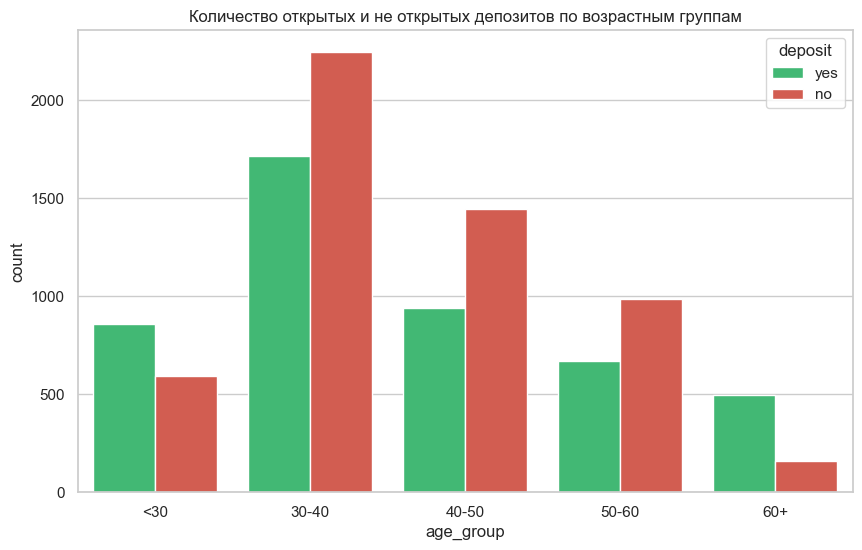

In [29]:
# Визуализация сравнения «открыл / не открыл» по возрастным группам. Для такой задачи лучше всего подходит столбчатая диаграмма с группировкой (grouped bar chart) или столбчатая с разделением внутри столбца (stacked).
# Чтобы чётко видеть различия между «yes» и «no», удобнее группированные столбцы с hue.

sns.set(style="whitegrid")

plt.figure(figsize=(10, 6))

# countplot автоматически считает количество наблюдений
sns.countplot(
    data=data_clean,
    x='age_group',
    hue='deposit',
    order=['<30', '30-40', '40-50', '50-60', '60+'],          # фиксируем порядок
    hue_order=['yes', 'no'],                                  # порядок легенды: сначала yes
    palette={'yes': '#2ecc71', 'no': '#e74c3c'}               # зелёный — открыл, красный — нет
)

plt.title('Количество открытых и не открытых депозитов по возрастным группам')

Более склонны открывать депозит, чем отказываться от открытия депозита в банке после рекламного предложения клиенты в возрастных группах меньше 30 и более 60 лет.

Посмотрим, как зависит соотношение успешных и неуспешных контактов с клиентами от категорий, к которым относятся клиенты:

семейное положение; уровень образования; сфера занятости.

Построим визуализации, отражающие количество тех, кто открыл депозит, и тех, кто его не открыл, для всех категорий предложенных выше трёх признаков.Оформляем диаграммы максимально наглядно и описываем полученный результат.

К каким категориям относится бόльшая часть людей? Среди каких групп населения есть тенденция соглашаться открывать депозит, а среди каких — отказываться?

### Задания 9 и 10

In [30]:
# постройте визуализации для открывших и неоткрывших депозит в зависимости от семейного статуса


In [31]:
# постройте визуализации для открывших и неоткрывших депозит в зависимости от образования

In [32]:
# постройте визуализации для открывших и неоткрывших депозит в зависимости от вида профессиональной занятости

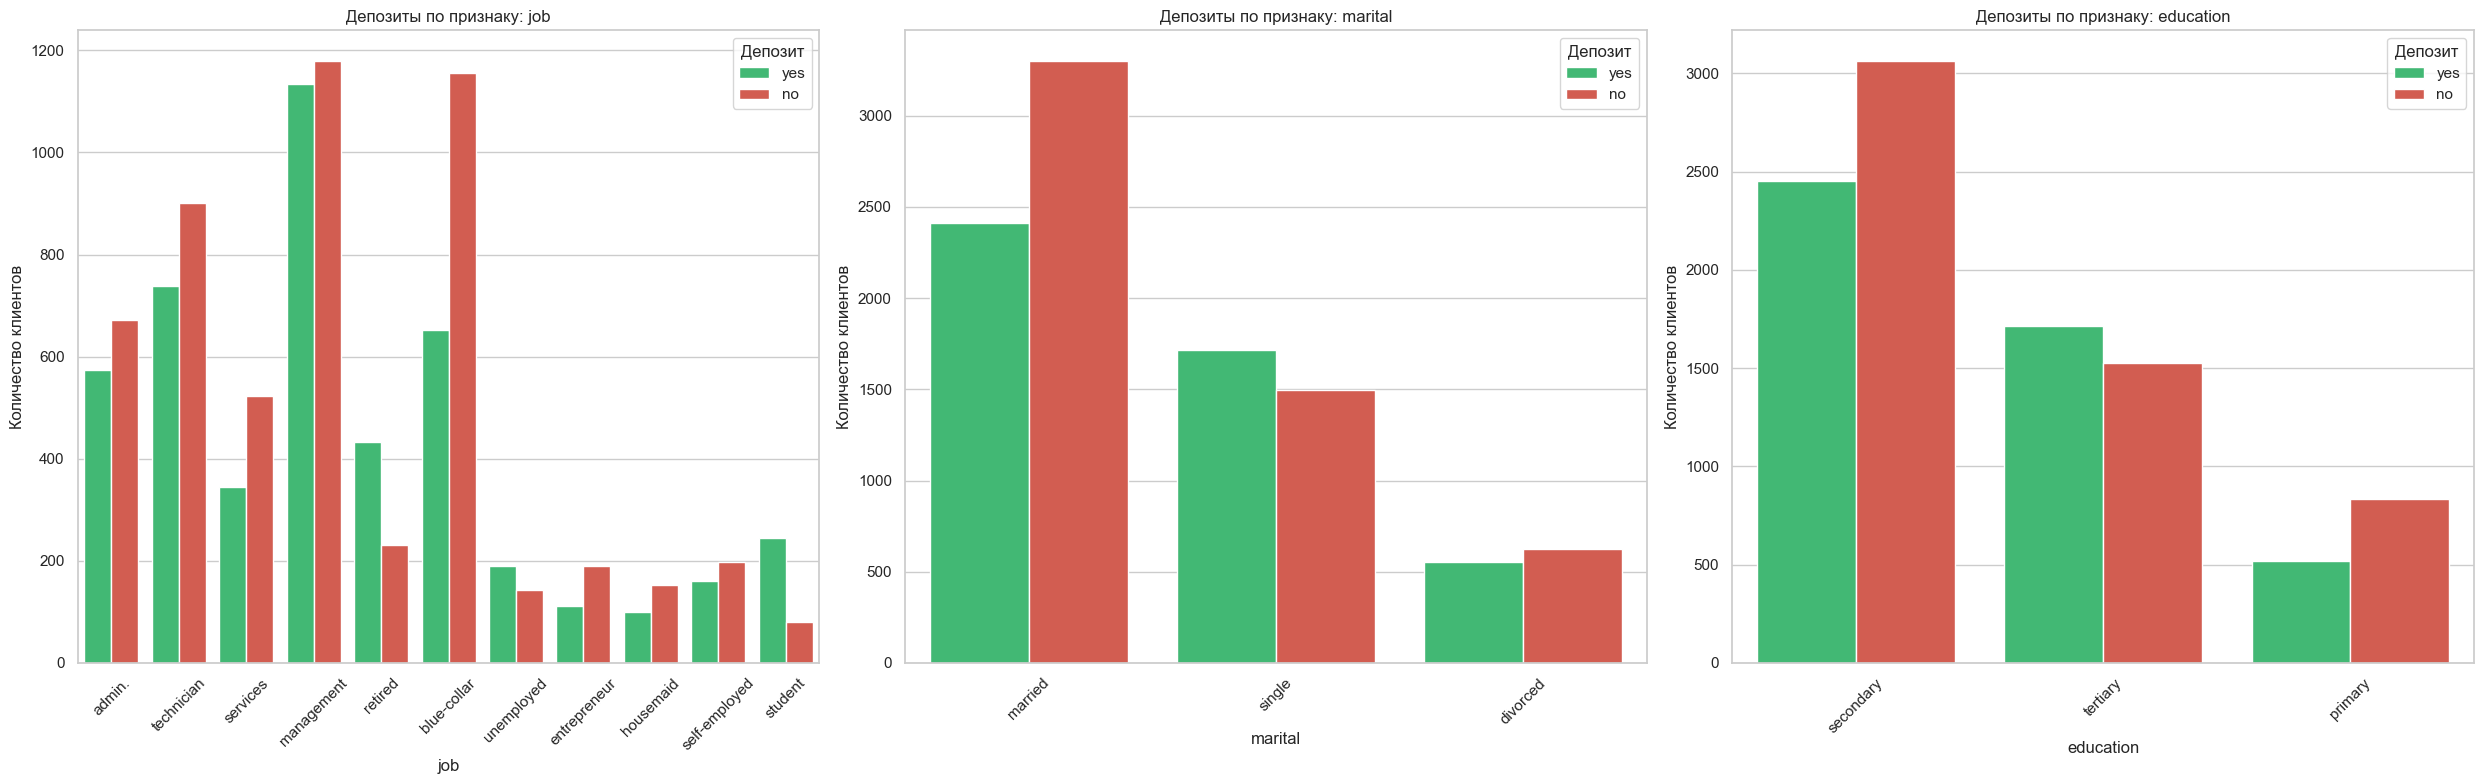

In [33]:
sns.set(style="whitegrid")

features = ['job', 'marital', 'education']
hue_order = ['yes', 'no']  
palette = {'yes': '#2ecc71', 'no': '#e74c3c'} 

fig, axes = plt.subplots(1, 3, figsize=(25, 8))

for ax, feat in zip(axes, features):
    sns.countplot(
        data=data_clean,
        x=feat,
        hue='deposit',
        ax=ax,
        hue_order=hue_order,
        palette=palette
    )
    ax.set_title(f'Депозиты по признаку: {feat}')
    ax.set_xlabel(feat)
    ax.set_ylabel('Количество клиентов')
    ax.tick_params(axis='x', rotation=45)
    ax.legend(title='Депозит')

plt.tight_layout()
plt.show()

Наибольшее число клиентов банка занято в сфере *management*. Они же наиболее часто открывают депозиты.

Тенденция открывать депозит, а не отказываться от его открытия есть для холостых клиентов (семейное положение *single*) и клиентов  с высшим образованием.

`Посмотрим на пересечения категорий`. 

Каких людей среди открывших депозит больше: одиноких с высшим образованием или разведённых с более низким уровнем образования?

Разделим таблицу на две части: для тех, кто открыл депозит, и для тех, кто не открыл. Для каждой части построим сводную диаграмму по уровню образования и семейному положению. Представим результаты в виде тепловых карт.

Различаются ли наиболее популярные группы для открывших депозит и для неоткрывших? Какой вывод можно сделать, исходя из полученных данных?

### Задание 11

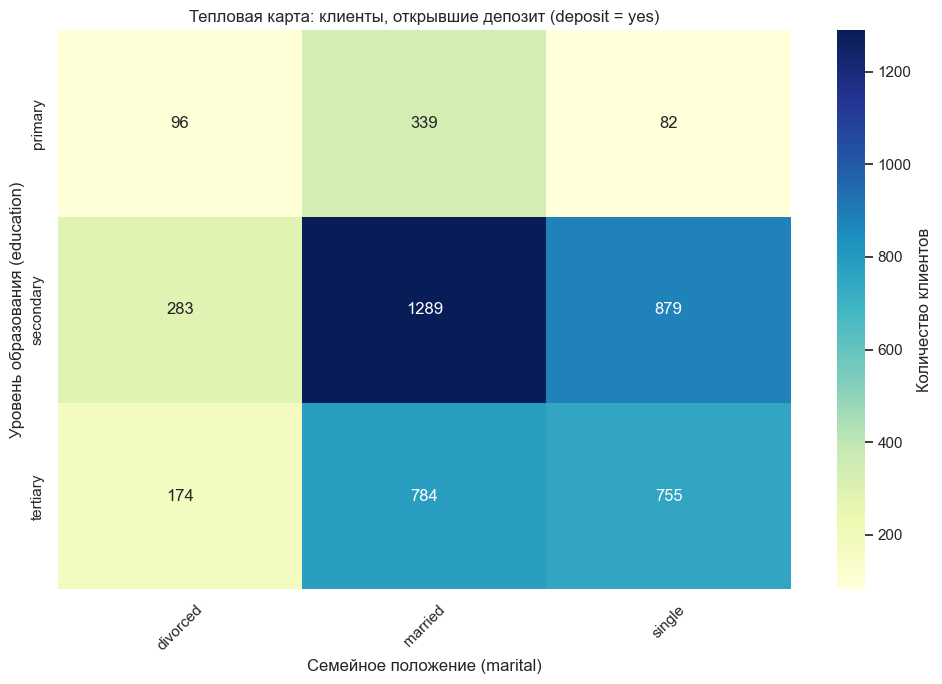

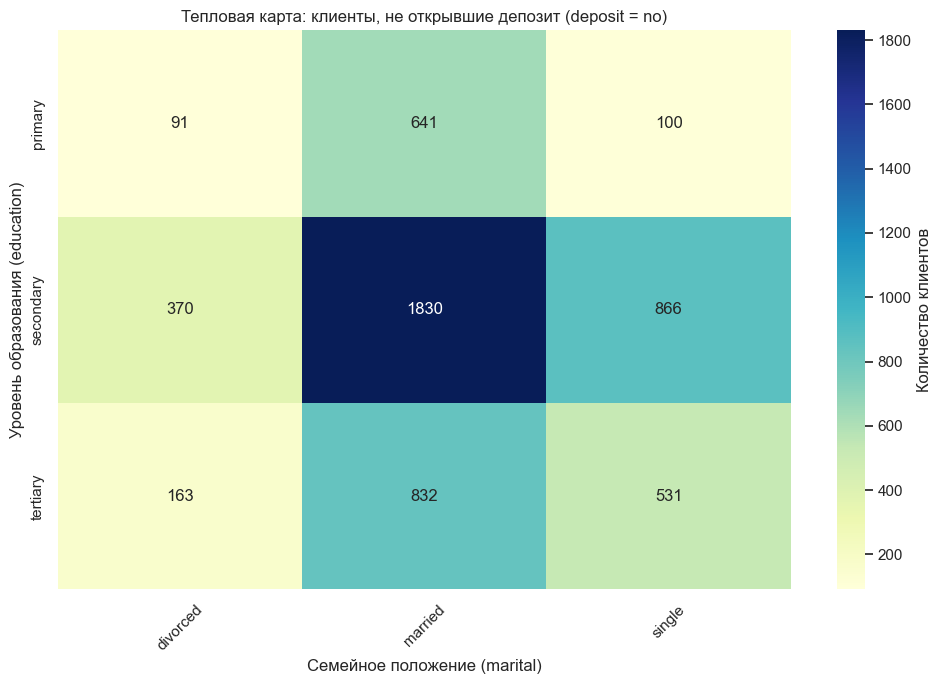

In [34]:
# постройте сводную таблицу, чтобы определить люди с каким образованием и семейным статусом наиболее многочисленны
#(если рассматривать тех, кто открыл депозит)

sns.set(style="whitegrid")

# Разделение на две части
df_yes = data_clean[data_clean['deposit'] == 'yes']
df_no = data_clean[data_clean['deposit'] == 'no']

def plot_heatmap(data, title):
    # Сводная таблица: строки — education, столбцы — marital, значения — количество
    pivot = pd.crosstab(data['education'], data['marital'])

    plt.figure(figsize=(10, 7))
    sns.heatmap(pivot, annot=True, fmt='d', cmap='YlGnBu', cbar_kws={'label': 'Количество клиентов'})
    plt.title(title)
    plt.xlabel('Семейное положение (marital)')
    plt.ylabel('Уровень образования (education)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

plot_heatmap(df_yes, 'Тепловая карта: клиенты, открывшие депозит (deposit = yes)')
plot_heatmap(df_no, 'Тепловая карта: клиенты, не открывшие депозит (deposit = no)')

### `Отлично!` 

Мы справились с разведывательным анализом и уже кое-что знаем о предоставленных данных: понимаем, какие в целом клиенты обслуживаются в банке, а также знаем, какие возрастные и социальные группы склонны чаще соглашаться на предложение банка.

Возможно необходимо потратить ещё какое-то время на поиски разных интересных паттернов и зависимостей в данных. 

Запоммнаем те факторы, которые кажутся хорошими претендентами на основных предикторов положительного исхода маркетингового взаимодействия.

## <center> Часть 3: преобразование данных

- Алгоритмы машинного обучения не могут обрабатывать категориальные признаки в их обычном виде. Поэтому необходимо преобразовать категориальные признаки в более удобный формат.

- Необходимо масштабировать и трансформировать некоторые признаки для того, чтобы улучшить качество модели.

- Надо отобрать признаки, которые мы будем использовать для обучения модели.

In [35]:
# Перед проведением преобразований проводим копирование промежуточного результата (датасета)

df_3 = data_clean.copy()

### Задание 1

In [36]:
# Преобразуйте уровни образования

from sklearn.preprocessing import LabelEncoder

# Инициализируем кодировщик
le = LabelEncoder()

# Обучаем на уникальных значениях признака education и сразу преобразуем колонку
df_3['education_encoded'] = le.fit_transform(df_3['education'])

# Смотрим соответствие категорий и кодов
mapping = dict(zip(le.classes_, range(len(le.classes_))))
print("Соответствие категорий и кодов:", mapping)

Соответствие категорий и кодов: {'primary': 0, 'secondary': 1, 'tertiary': 2}


In [37]:
# Контрольный вопрос
# Найти сумму получившихся значений для признака education
total_sum = df_3['education_encoded'].sum()
print("Сумма значений признака education_encoded:", total_sum)

Сумма значений признака education_encoded: 11995


Ранее мы создали порядковую переменную для возраста. Обработаем её по такому же принципу, чтобы её можно было использовать при обучении модели.

In [38]:
# Проводим кодирование переменной 'age_group'

import joblib

le_age = LabelEncoder()

# fit_transform: обучаем на уникальных значениях и сразу кодируем
df_3['age_group_encoded'] = le_age.fit_transform(df_3['age_group'])

# Сохраняем энкодер для применения на тестовой выборке/новых данных
joblib.dump(le_age, 'age_group_label_encoder.joblib')

print("Соответствие категорий и кодов:", dict(zip(le_age.classes_, range(len(le_age.classes_)))))

Соответствие категорий и кодов: {'30-40': 0, '40-50': 1, '50-60': 2, '60+': 3, '<30': 4}


### Задания 2 и 3

In [39]:
# преобразуйте бинарные переменные в представление из нулей и единиц

# перекодируем переменную deposit таким образом, чтобы вместо yes она принимала значение 1, а вместо no — 0.
deposit_mapping = {'yes': 1, 'no': 0}
df_3['deposit_binary'] = df_3['deposit'].map(deposit_mapping)

In [40]:
# Перекодируем бинарные переменные, которых у нас три: 'default'; 'housing'; 'loan' таким же образом

binary_cols = ['default', 'housing', 'loan']
mapping = {'yes': 1, 'no': 0}

for col in binary_cols:
    df_3[col + '_bin'] = df_3[col].map(mapping)

In [41]:
# Контрольные задания

# Вычислить стандартное отклонение по преобразованной в корректный вид целевой переменной deposit.
std_deposit = df_3['deposit_binary'].std()
print("Стандартное отклонение deposit_binary:", std_deposit)

Стандартное отклонение deposit_binary: 0.4986712532452124


In [42]:
# Вычислить среднее арифметическое для каждой из получившихся переменных 'default', 'housing', 'loan', сложить три результата и в качестве ответа вывести итог, округлив его до трёх знаков после точки-разделителя.

cols = ['default_bin', 'housing_bin', 'loan_bin']

# Вычисляем среднее для каждой колонки (пропуски автоматически игнорируются)
means = [df_3[col].mean() for col in cols]

# Суммируем три средних
total = sum(means)

# Округляем до 3 знаков после запятой
result = round(total, 3)

print(f"Сумма средних арифметических: {result}")

Сумма средних арифметических: 0.635


### Задание 4

Теперь нам необходимо преобразовать номинальные переменные, которые могут принимать несколько различных значений. Это следующие переменные:

'job'; 'marital'; 'contact'; 'month'; 'poutcome'.

Создадим для них dummy-переменные и добавим их в набор данных.

In [43]:
# создайте дамми-переменные

# Список номинальных признаков для кодирования
cat_cols = ['job', 'marital', 'contact', 'month', 'poutcome']

# Создаём dummy‑переменные и добавляем их к df_3, сохраняя исходные колонки
df_3 = pd.concat(
    [df_3, pd.get_dummies(df_3[cat_cols], prefix=cat_cols, prefix_sep='_')],
    axis=1
)

# Проверка результата (первые 5 строк и новые колонки)
print(df_3.head())
print(df_3.columns.tolist())

   age         job  marital  education default  balance housing loan  contact  \
0   59      admin.  married  secondary      no   2343.0     yes   no  unknown   
1   56      admin.  married  secondary      no     45.0      no   no  unknown   
2   41  technician  married  secondary      no   1270.0     yes   no  unknown   
3   55    services  married  secondary      no   2476.0     yes   no  unknown   
4   54      admin.  married   tertiary      no    184.0      no   no  unknown   

   day  ... month_jun  month_mar  month_may  month_nov  month_oct month_sep  \
0    5  ...     False      False       True      False      False     False   
1    5  ...     False      False       True      False      False     False   
2    5  ...     False      False       True      False      False     False   
3    5  ...     False      False       True      False      False     False   
4    5  ...     False      False       True      False      False     False   

  poutcome_failure poutcome_other  pou

In [44]:
# Удаляем уже ненужные признаки
cols_to_drop = ['age','education', 'age_group', 'deposit', 'default', 'housing', 'loan']

df_3_dum = df_3.drop(columns=cols_to_drop, errors='ignore')

# Проверка оставшихся колонок
print(df_3_dum.columns.tolist())

['job', 'marital', 'balance', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'education_encoded', 'age_group_encoded', 'deposit_binary', 'default_bin', 'housing_bin', 'loan_bin', 'job_admin.', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'marital_divorced', 'marital_married', 'marital_single', 'contact_cellular', 'contact_telephone', 'contact_unknown', 'month_apr', 'month_aug', 'month_dec', 'month_feb', 'month_jan', 'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'month_oct', 'month_sep', 'poutcome_failure', 'poutcome_other', 'poutcome_success', 'poutcome_unknown']


### Задания 5 и 6

Теперь оценим мультиколлинеарность и взаимосвязь признаков с целевой переменной. Для этого построим матрицу корреляций. Дополним её тепловой картой, отражающей результат.

В качестве дополнения визуализации к этому заданию построим столбчатую диаграмму для ранжированных коэффициентов корреляции.

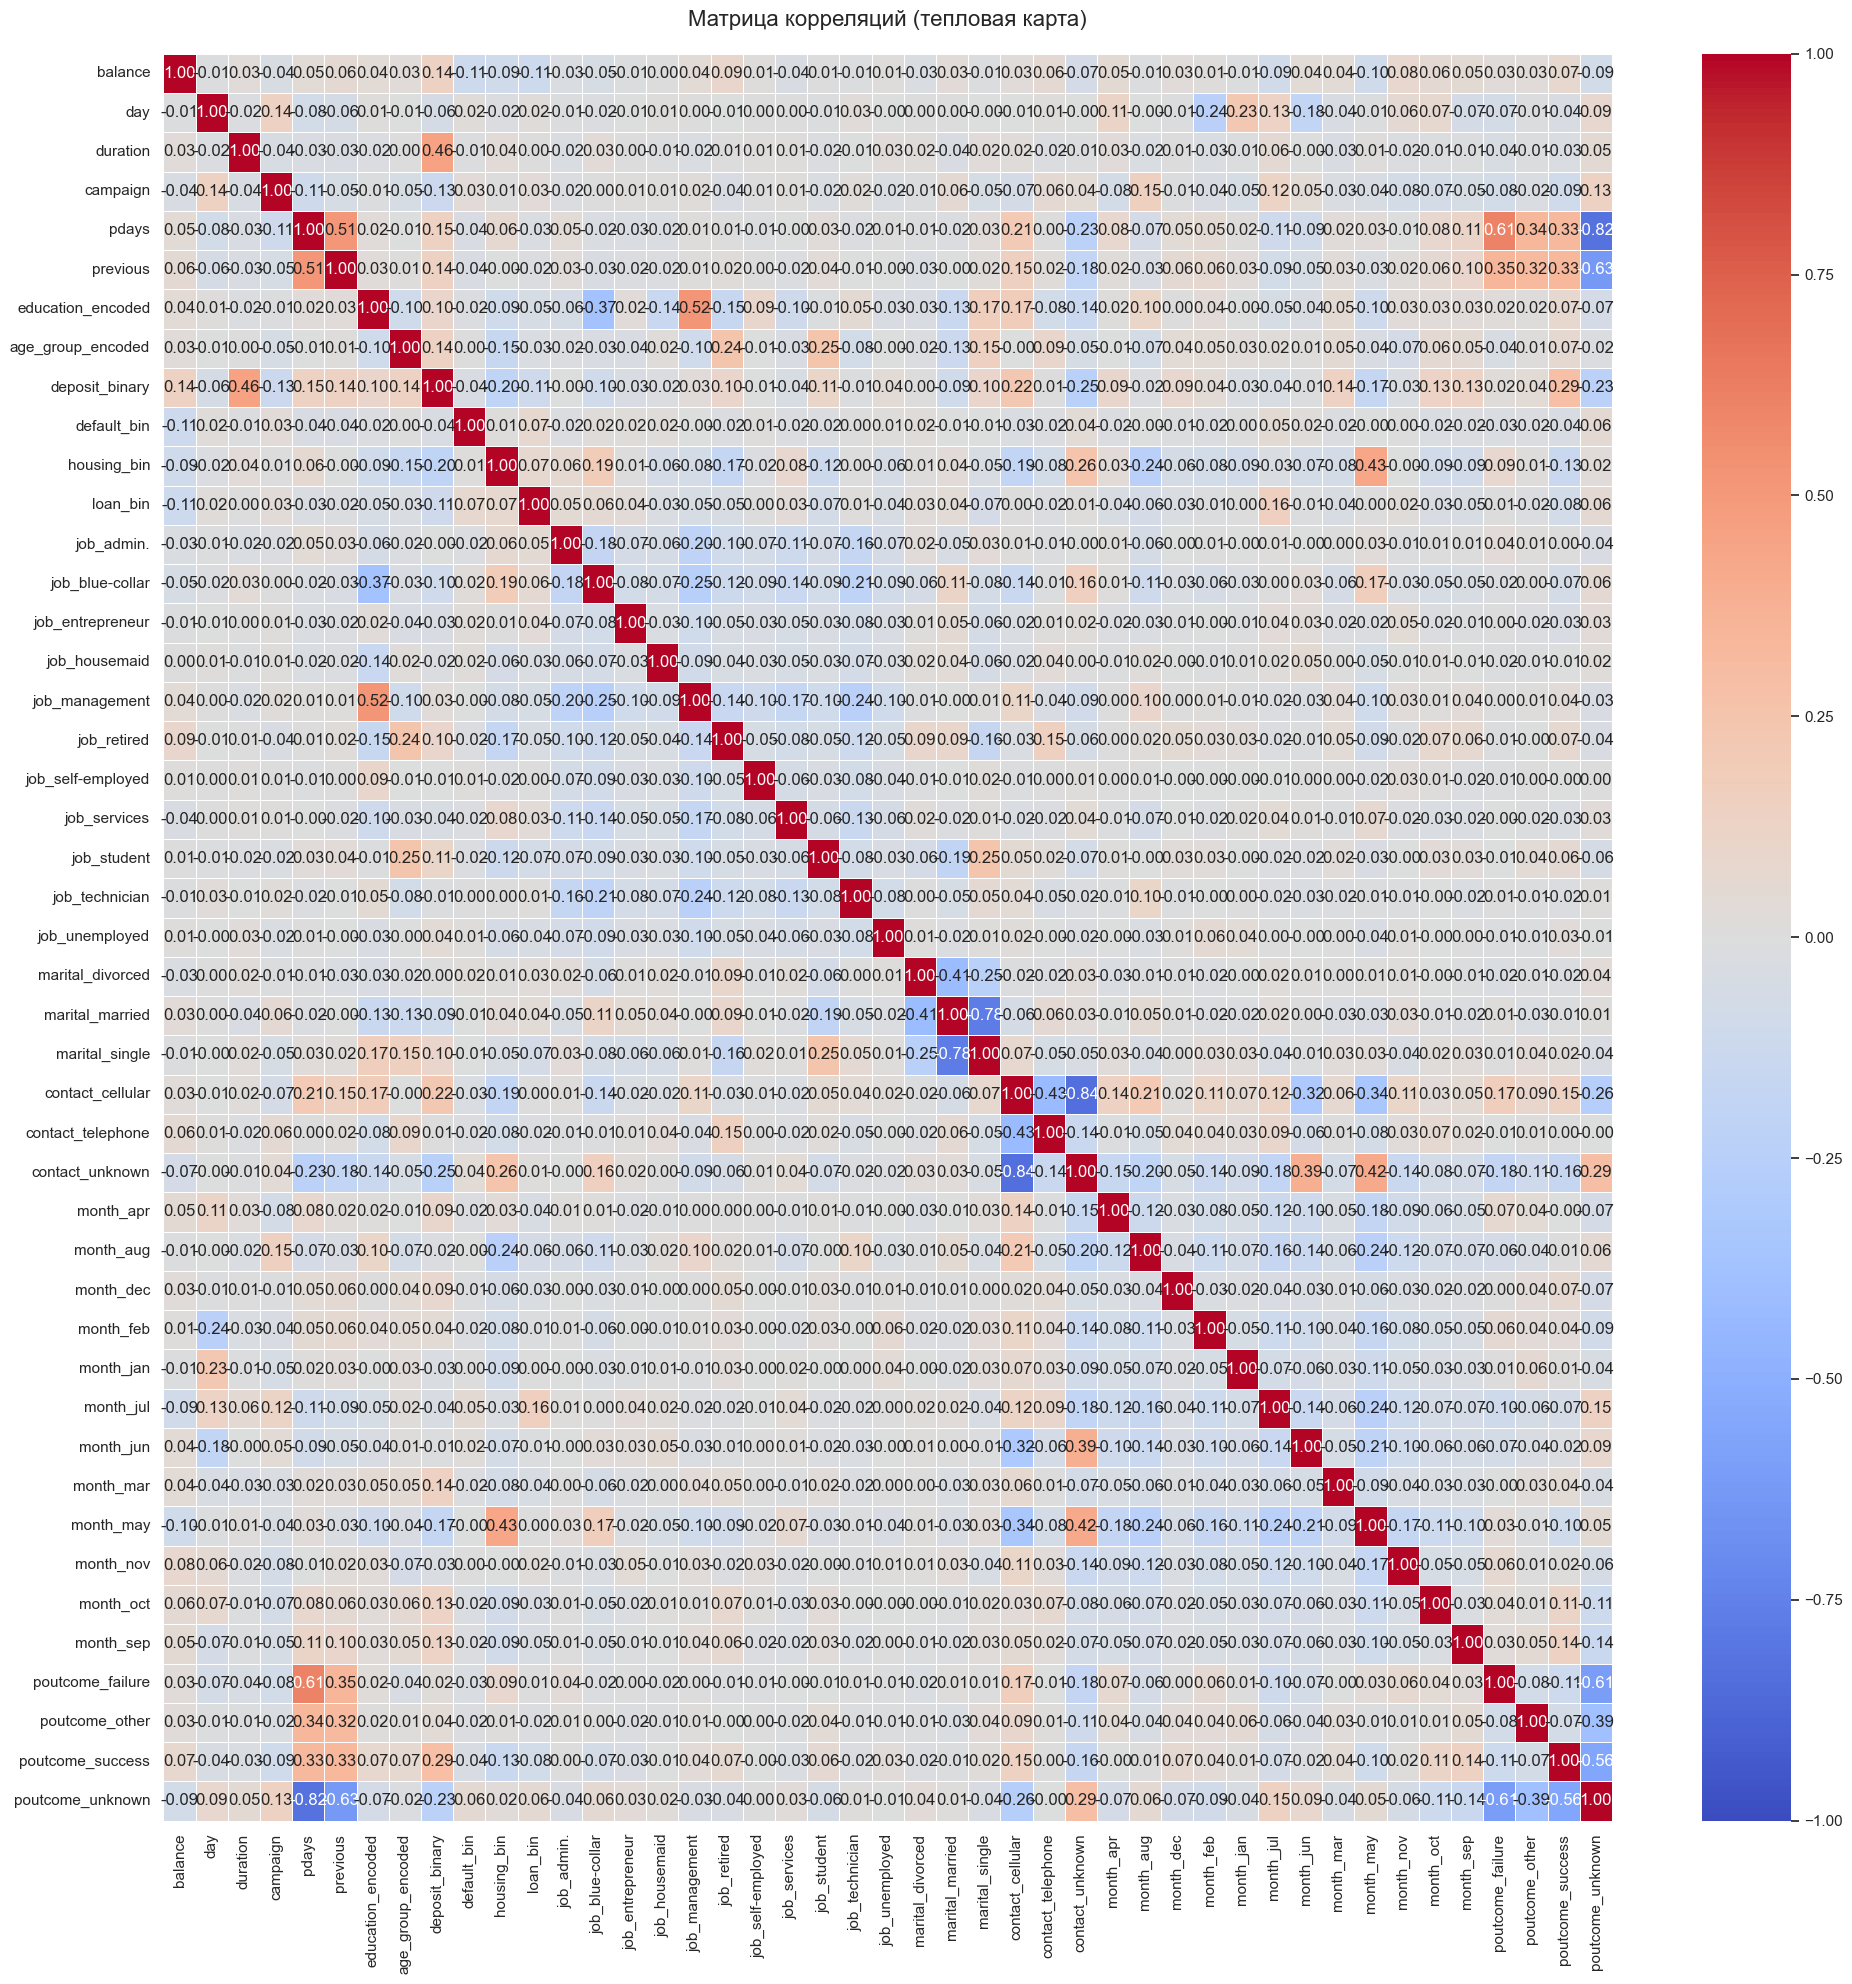

In [45]:
# постройте корреляционную матрицу и оцените данные на предмет наличия мультиколлинеарности

# Матрица корреляций (только для числовых признаков)
corr_matrix = df_3_dum.corr(numeric_only=True)

# Тепловая карта (heatmap)
plt.figure(figsize=(20, 20))
sns.heatmap(
    corr_matrix,
    annot=True,          # показывать значения в ячейках
    fmt=".2f",           # формат чисел (2 знака после запятой)
    cmap="coolwarm",     # цветовая схема: синий — отрицательная, красный — положительная
    vmin=-1, vmax=1,     # границы шкалы
    linewidths=0.5,      # тонкие линии между ячейками
    center=0             # нейтральная точка (0) будет в центре палитры
)
plt.title("Матрица корреляций (тепловая карта)", fontsize=16, pad=20)
plt.tight_layout()
plt.show()

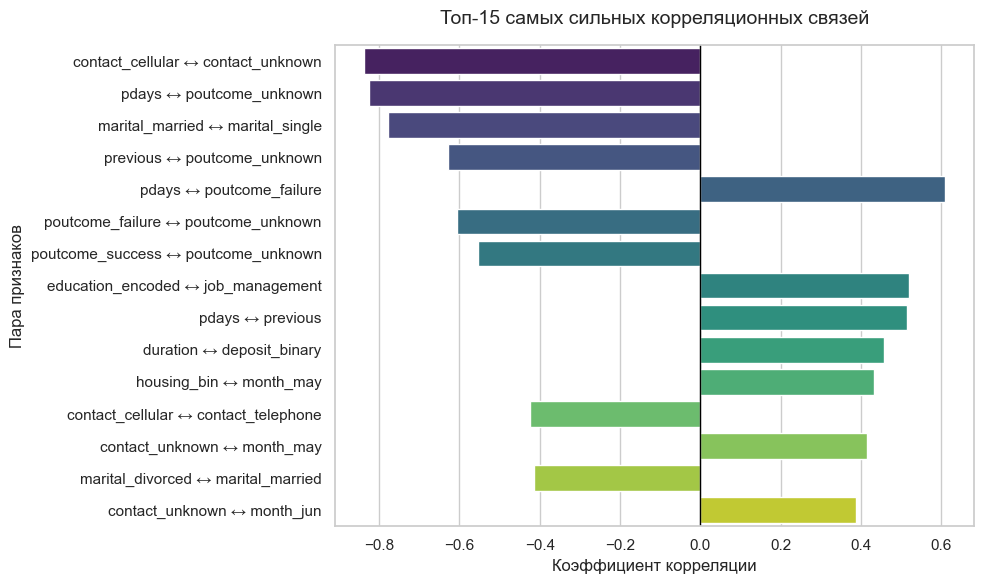

In [46]:
# Ранжированные коэффициенты корреляции (столбчатая диаграмма)
# Преобразуем матрицу корреляций в длинный формат и убираем дубли (корреляция A-B = B-A)
corr_long = corr_matrix.unstack()
corr_long = corr_long.drop_duplicates()

# Исключаем корреляцию признака с самим собой (диагональ = 1)
corr_long = corr_long[corr_long != 1]

# Сортируем по абсолютной величине корреляции (чтобы видеть самые сильные связи)
corr_sorted = corr_long.sort_values(key=abs, ascending=False)

# Для наглядности можно взять топ-N самых сильных связей (например, топ-15)
top_n = 15
corr_top = corr_sorted.head(top_n)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=corr_top.values,
    y=[f"{idx[0]} ↔ {idx[1]}" for idx in corr_top.index],
    palette="viridis"
)
plt.axvline(0, color="black", linewidth=1)  # линия нуля
plt.xlabel("Коэффициент корреляции", fontsize=12)
plt.ylabel("Пара признаков", fontsize=12)
plt.title(f"Топ-{top_n} самых сильных корреляционных связей", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

In [47]:
# копируем промежуточный результат
df_4 = df_3_dum.copy()

In [48]:
 df_4['deposit'] =  df_4['deposit_binary']

In [49]:
df_4 = df_4.drop(['deposit_binary'], axis=1)
df_4

,job,marital,balance,contact,day,month,duration,campaign,pdays,previous,...,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown,deposit
0,admin.,married,2343.0,unknown,5,may,1042,1,-1,0,...,False,True,False,False,False,False,False,False,True,1
1,admin.,married,45.0,unknown,5,may,1467,1,-1,0,...,False,True,False,False,False,False,False,False,True,1
2,technician,married,1270.0,unknown,5,may,1389,1,-1,0,...,False,True,False,False,False,False,False,False,True,1
3,services,married,2476.0,unknown,5,may,579,1,-1,0,...,False,True,False,False,False,False,False,False,True,1
4,admin.,married,184.0,unknown,5,may,673,2,-1,0,...,False,True,False,False,False,False,False,False,True,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,blue-collar,single,1.0,cellular,20,apr,257,1,-1,0,...,False,False,False,False,False,False,False,False,True,0
11158,services,married,733.0,unknown,16,jun,83,4,-1,0,...,False,False,False,False,False,False,False,False,True,0
11159,technician,single,29.0,cellular,19,aug,156,2,-1,0,...,False,False,False,False,False,False,False,False,True,0
11160,technician,married,0.0,cellular,8,may,9,2,172,5,...,False,True,False,False,False,True,False,False,False,0


Теперь нам необходимо определить целевую переменную и предикторы, а также разделить выборку на обучающую и тестовую.

При разбиении зададим параметр random_state = 42, а размер тестовой выборки возьмём за 0.33. Добавим аргумент, определяющий сохранение соотношений целевого признака.

### Задания 7 и 8

In [50]:
X = df_4.drop(['deposit'], axis=1)
y = df_4['deposit']
 
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state = 42, test_size = 0.33)

In [51]:
# рассчитайте необходимые показатели

print("Размер обучающей выборки:", len(X_train))
print("Размер тестовой выборки:", len(X_test))
print("Доля тестовой выборки: {:.2%}".format(len(X_test) / len(df_3)))

Размер обучающей выборки: 6770
Размер тестовой выборки: 3335
Доля тестовой выборки: 33.00%


In [52]:
# Определить среднее значение целевой переменной на тестовой выборке. Ответ округлить до двух знаков после точки-разделителя.

mean_deposit_test = y_test.mean()
mean_deposit_test_rounded = round(mean_deposit_test, 2)

print(f"Среднее значение целевой переменной на тестовой выборке: {mean_deposit_test_rounded}")

Среднее значение целевой переменной на тестовой выборке: 0.46


### Задание 9

На данный момент у нас достаточно много признаков: скорее всего, не все из них будут важны. Оставим лишь те, которые сильнее всего связаны с целевой переменной и точно будут вносить вклад в повышение качества модели.

С помощью SelectKBest отберём 15 признаков, наилучшим образом подходящих для использования в задаче. Отбор реализуем по обучающей выборке, используя параметр score_func = f_classif.

Помним, что на данном этапе вам необходимо оставить только те признаки, которые содержат лишь числовые значения.

In [53]:
# с помощью SelectKBest отберите 15 наиболее подходящих признаков

from sklearn.feature_selection import SelectKBest, f_classif

# Включаем bool и сразу приводим всё к float
X_train_num = X_train.select_dtypes(include=[np.number, bool]).astype(float)
X_test_num = X_test.select_dtypes(include=[np.number, bool]).astype(float)

# отбираем признаки через SelectKBest с F‑статистикой
selector = SelectKBest(score_func=f_classif, k=15)
X_train_selected = selector.fit_transform(X_train_num, y_train) # учим модель, какие признаки важны, и преобразуем данные
X_test_selected = selector.transform(X_test_num)

selected_mask = selector.get_support()
selected_features = X_train_num.columns[selected_mask]
print(selected_features.tolist())

['balance', 'duration', 'campaign', 'pdays', 'previous', 'age_group_encoded', 'housing_bin', 'contact_cellular', 'contact_unknown', 'month_mar', 'month_may', 'month_oct', 'month_sep', 'poutcome_success', 'poutcome_unknown']


In [54]:
X_train = X_train_selected
X_test = X_test_selected

### Задание 10

Теперь данные необходимо нормализовать. Будем использовать *min-max*-нормализацию. Помним, что нормализация требуется для предикторов, а не для целевой переменной.

Нормализуем предикторы в обучающей и тестовой выборках.

In [55]:
# нормализуйте данные с помощью minmaxsxaler

from sklearn.preprocessing import MinMaxScaler

# Инициализируем скалер (по умолчанию диапазон [0, 1])
scaler = MinMaxScaler(feature_range=(0, 1))

# Обучаем скалер только на обучающей выборке (чтобы не было утечки данных)
X_train_scaled = scaler.fit_transform(X_train)

# Применяем тот же скалер к тестовой выборке
X_test_scaled = scaler.transform(X_test)

print("Форма X_train_scaled:", X_train_scaled.shape)
print("Форма X_test_scaled:", X_test_scaled.shape)


Форма X_train_scaled: (6770, 15)
Форма X_test_scaled: (3335, 15)


### `Контроль` 

Рассчитать среднее арифметическое для первого предиктора (т. е. для первого столбца матрицы) из тестовой выборки.

In [56]:
# Среднее арифметическое первого предиктора (первого столбца) тестовой выборки
mean_first_predictor = np.mean(X_test_scaled[:, 0])

print(f"Среднее значение первого предиктора в тестовой выборке: {mean_first_predictor:.4f}")

Среднее значение первого предиктора в тестовой выборке: 0.4682


# <center> Часть 4: Решение задачи классификации: логистическая регрессия и решающие деревья

### Задание 1

In [57]:
# обучите логистическую регрессию и рассчитайте метрики качества

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

X_train = X_train_scaled
X_test = X_test_scaled

model = LogisticRegression(
    solver='sag',          # алгоритм оптимизации
    random_state=42,       # воспроизводимость
    max_iter=1000,         # число итераций
    n_jobs=-1              # использовать все ядра
)
model.fit(X_train, y_train)

# Предсказания на тестовой выборке
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Оценка качества
acc = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba) # Receiver Operating Characteristic — Area Under Curve — метрика качества бинарного классификатора, которая показывает, насколько хорошо модель разделяет два класса 

print(f"Accuracy на тесте: {acc:.4f}")
print(f"ROC-AUC на тесте: {roc_auc:.4f}")

Accuracy на тесте: 0.8048
ROC-AUC на тесте: 0.8879


### Задания 2,3,4

In [58]:
# обучите решающие деревья, настройте максимальную глубину

from sklearn.tree import DecisionTreeClassifier

# Создание и обучение модели решающего дерева
dt_model = DecisionTreeClassifier(
    criterion='entropy',   # критерий разбиения — энтропия
    random_state=42        # воспроизводимость результатов
    # остальные параметры — по умолчанию
)
dt_model.fit(X_train, y_train)

# Предсказания на тестовой выборке
y_pred = dt_model.predict(X_test)
y_pred_proba = dt_model.predict_proba(X_test)[:, 1]

# Оценка качества модели
acc_dt = accuracy_score(y_test, y_pred)
roc_auc_dt = roc_auc_score(y_test, y_pred_proba)

print(f"Accuracy на тесте: {acc_dt:.4f}")
print(f"ROC-AUC на тесте: {roc_auc_dt:.4f}")

Accuracy на тесте: 0.7505
ROC-AUC на тесте: 0.7482


Переберём различные максимальные глубины деревьев и найдём глубину дерева, для которой будет максимальное значение метрики *accuracy*, но при этом ещё не будет наблюдаться переобучения 

(т. е. не будет расти качество на обучающей выборке при неизменном качестве на тестовой).

Оптимальная глубина (по Accuracy на тесте): 7
Accuracy на тесте при этой глубине: 0.8171


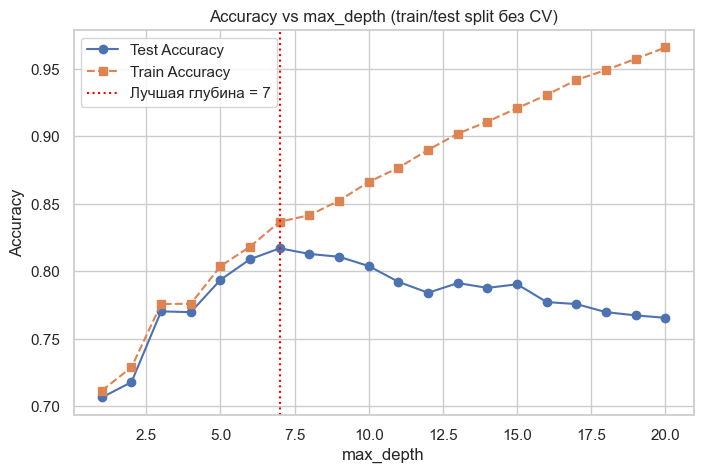

In [59]:
depths = list(range(1, 21))  # от 1 до 20
test_accs = []
train_accs = []

for d in depths:
    dt = DecisionTreeClassifier(
        criterion='entropy',
        max_depth=d,
        random_state=42
    )
    dt.fit(X_train, y_train)

    train_pred = dt.predict(X_train)
    test_pred = dt.predict(X_test)

    train_accs.append(accuracy_score(y_train, train_pred))
    test_accs.append(accuracy_score(y_test, test_pred))

# Находим глубину с максимальным Accuracy на тесте
best_idx = max(range(len(test_accs)), key=lambda i: test_accs[i])
best_depth = depths[best_idx]
best_test_acc = test_accs[best_idx]

print(f"Оптимальная глубина (по Accuracy на тесте): {best_depth}")
print(f"Accuracy на тесте при этой глубине: {best_test_acc:.4f}")

# Визуализация
plt.figure(figsize=(8, 5))
plt.plot(depths, test_accs, marker='o', label='Test Accuracy')
plt.plot(depths, train_accs, marker='s', linestyle='--', label='Train Accuracy')
plt.axvline(best_depth, color='red', linestyle=':', label=f'Лучшая глубина = {best_depth}')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.title('Accuracy vs max_depth (train/test split без CV)')
plt.show()

### Задание 5

Разумеется, у каждой модели может быть множество параметров. Перебирать их вручную, чтобы получить наилучшее качество, долго и трудозатратно. Поэтому мы можем использовать оптимизацию: можно перебрать сразу большое количество 

комбинаций различных параметров и выбрать тот вариант, при котором модель будет давать наиболее точный прогноз. Реализуtv оптимизацию гиперпараметров с помощью *GridSearch*, перебрав следующие параметры:

'*min_samples_split*': [2, 5, 7, 10];  '*max_depth*':[3,5,7].

Оценим метрику  на тестовой выборке для наилучшей комбинации перебираемых параметров.

In [60]:
# подберите оптимальные параметры с помощью gridsearch

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import f1_score, classification_report, confusion_matrix

# Параметры для перебора
param_grid = {
    'min_samples_split': [2, 5, 7, 10],
    'max_depth': [3, 5, 7]
}

# Инициализация модели (criterion и random_state фиксируем)
dt = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

# GridSearchCV: ищем лучшую комбинацию по F1 (по умолчанию для бинарной задачи — F1 для положительного класса)
grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,                 # 5 фолдов кросс-валидации внутри поиска (это корректно даже при наличии отдельного test)
    scoring='f1',         # оптимизация по F1
    n_jobs=-1,            # параллельные вычисления
    verbose=1             # вывод прогресса
)

grid_search.fit(X_train, y_train)

print("Лучшая комбинация параметров:", grid_search.best_params_)
print("Лучший CV F1 на обучении:", grid_search.best_score_)

# Оценка на тестовой выборке (это и есть итоговая оценка качества)
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
f1_test = f1_score(y_test, y_pred)

print(f"F1 на тестовой выборке: {f1_test:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Лучшая комбинация параметров: {'max_depth': 7, 'min_samples_split': 10}
Лучший CV F1 на обучении: 0.7962156923133622
F1 на тестовой выборке: 0.8071

Classification report:
              precision    recall  f1-score   support

           0       0.84      0.82      0.83      1790
           1       0.79      0.82      0.81      1545

    accuracy                           0.82      3335
   macro avg       0.82      0.82      0.82      3335
weighted avg       0.82      0.82      0.82      3335

Confusion matrix:
[[1461  329]
 [ 277 1268]]


# <center> Часть 5: Решение задачи классификации: ансамбли моделей и построение прогноза

### Задание 1

Мы обучили модели решающих деревьев, и теперь пришла пора объединить их в случайный лес. Обучим случайный лес со следующими параметрами:

*n_estimators* = `100`; *criterion* = '`gini`'; *min_samples_leaf* = `5`; *max_depth* = `10`; *random_state* = `42`.

Оценим различные метрики для построенной модели на тестовой выборке.

In [61]:
# обучим на наших данных случайный лес

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score

# Инициализация модели с заданными параметрами
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    min_samples_leaf=5,
    max_depth=10,
    random_state=42
)

# Обучение на обучающей выборке
rf_model.fit(X_train, y_train)

# Прогноз на тестовой выборке (классы)
y_pred = rf_model.predict(X_test)

# Прогноз вероятностей (для ROC-AUC берём вероятности класса 1)
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Оценка качества
acc_rf = accuracy_score(y_test, y_pred)
auc_rf = roc_auc_score(y_test, y_prob)
rec = recall_score(y_test, y_pred)

# Выводим результаты оценки
print(f"Accuracy на тесте: {acc_rf:.4f}")
print(f"ROC-AUC на тесте: {auc_rf:.4f}")
print(f"Recall на тесте: {rec:.4f}")

# Дополнительно: подробный отчёт по метрикам (Precision, Recall, F1 для каждого класса)
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=['no', 'yes']))

Accuracy на тесте: 0.8237
ROC-AUC на тесте: 0.9028
Recall на тесте: 0.8298

Classification report:
              precision    recall  f1-score   support

          no       0.85      0.82      0.83      1790
         yes       0.80      0.83      0.81      1545

    accuracy                           0.82      3335
   macro avg       0.82      0.82      0.82      3335
weighted avg       0.82      0.82      0.82      3335



### Задания 2 и 3

Дата-сайентист не должен останавливаться на одной модели — он должен пробовать все доступные варианты. Поэтому попробуем сравнить полученные результаты с моделью **градиентного бустинга**. Параметры:

learning_rate = 0.05; n_estimators = 300; min_samples_leaf = 5; max_depth = 5; random_state = 42.

Для построенной модели оценим метрику *F1* на тестовой выборке. 

In [62]:
# используйте для классификации градиентный бустинг и сравните качество со случайным лесом

from sklearn.ensemble import GradientBoostingClassifier

# Инициализация модели градиентного бустинга с заданными параметрами
gb_model = GradientBoostingClassifier(
    learning_rate=0.05,
    n_estimators=300,
    min_samples_leaf=5,
    max_depth=5,
    random_state=42
)

# Обучение на обучающей выборке
gb_model.fit(X_train, y_train)

# Прогноз на тестовой выборке (классы)
y_pred_gb = gb_model.predict(X_test)

# Прогноз вероятностей (для ROC-AUC берём вероятности класса 1)
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

# Оценка метрики F1
f1 = f1_score(y_test, y_pred_gb)
print(f"F1 на тесте: {f1:.4f}")

# Оценка AUK
auc_gb = roc_auc_score(y_test, y_prob_gb)
print(f"ROC-AUC на тесте: {auc_gb:.4f}")

# Дополнительно: подробный отчёт по метрикам (Precision, Recall, F1 для каждого класса)
print("\nClassification report:")
print(classification_report(y_test, y_pred_gb, target_names=['no', 'yes']))

F1 на тесте: 0.8168
ROC-AUC на тесте: 0.8997

Classification report:
              precision    recall  f1-score   support

          no       0.85      0.82      0.84      1790
         yes       0.80      0.83      0.82      1545

    accuracy                           0.83      3335
   macro avg       0.83      0.83      0.83      3335
weighted avg       0.83      0.83      0.83      3335



`Вывод:`  Если посмотреть метрики в целом, то более качественный прогноз (с небольшим преимуществом) даёт модель случайного леса и для бизнес‑задачи она предпочтительнее модели градиентного бустинга.

### Задание 4

In [63]:
# объедините уже известные вам алгоритмы с помощью стекинга

from sklearn.ensemble import StackingClassifier
from sklearn.metrics import precision_score, accuracy_score, f1_score, roc_auc_score, recall_score, classification_report


# Базовые модели с теми же параметрами, что и ранее

# Решающее дерево
dt_model = DecisionTreeClassifier(
    max_depth=10,
    min_samples_leaf=5,
    random_state=42
)

# Логистическая регрессия
lr_model = LogisticRegression(
    solver='sag',
    random_state=42,
    max_iter=1000
)

# Градиентный бустинг
gb_model = GradientBoostingClassifier(
    learning_rate=0.05,
    n_estimators=300,
    min_samples_leaf=5,
    max_depth=5,
    random_state=42
)

# Метамодель — логистическая регрессия
meta_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

# Стекинг: объединяем базовые модели, метамодель — поверх их прогнозов
estimators = [
    ('dt', dt_model),
    ('lr', lr_model),
    ('gb', gb_model)
]

stacking_model = StackingClassifier(
    estimators=estimators,
    final_estimator=meta_model,
    cv=5  # кросс-валидация для генерации мета-признаков
)

# Обучение стекинга
stacking_model.fit(X_train, y_train)

# Прогноз на тестовой выборке
y_pred_stack = stacking_model.predict(X_test)
y_prob_stack = stacking_model.predict_proba(X_test)[:, 1]


# Precision для класса 1 («yes»)
prec = precision_score(y_test, y_pred_stack, pos_label=1)

# Остальные метрики (для контекста)
acc = accuracy_score(y_test, y_pred_stack)
f1 = f1_score(y_test, y_pred_stack)
auc = roc_auc_score(y_test, y_prob_stack)
rec = recall_score(y_test, y_pred_stack, pos_label=1)

print(f"Precision (class 1): {prec:.4f}")
print(f"Accuracy:            {acc:.4f}")
print(f"F1:                  {f1:.4f}")
print(f"ROC-AUC:             {auc:.4f}")
print(f"Recall (class 1):    {rec:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred_stack, target_names=['no', 'yes']))
 

Precision (class 1): 0.8076
Accuracy:            0.8225
F1:                  0.8087
ROC-AUC:             0.9003
Recall (class 1):    0.8097

Classification report:
              precision    recall  f1-score   support

          no       0.84      0.83      0.83      1790
         yes       0.81      0.81      0.81      1545

    accuracy                           0.82      3335
   macro avg       0.82      0.82      0.82      3335
weighted avg       0.82      0.82      0.82      3335



Не все признаки одинаково хорошо предсказывают результат маркетинговой кампании. Для того чтобы отобрать наиболее значимые для нас аспекты, на которые надо будет обратить внимание при реализации следующей акции, 

выберем три признака, дающих наибольший вклад в итоговые результаты.

### Задание 5

Определяем три признака, дающих наибольший вклад в предсказания результатов маркетинговой кампании.

In [64]:
# Оценить, какие признаки демонстрируют наибольшую  важность в модели градиентного бустинга

import numpy as np

# Получаем имена признаков (важно: порядок должен совпадать с тем, на чём обучали модель)
feature_names = selected_features

gb_model.fit(X_train, y_train)
importances = gb_model.feature_importances_

feat_imp = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)

print(feat_imp.head(3))

             feature  importance
1           duration    0.501987
13  poutcome_success    0.116264
8    contact_unknown    0.073792


### Задания 6,7,8

Один из более продвинутых вариантов оптимизации гиперпараметров — фреймворк Optuna. Применим его для оптимизации гиперпараметров. Для перебора возьмём случайный лес и следующие параметры:

n_estimators = trial.suggest_int('n_estimators', 100, 200, 1); max_depth = trial.suggest_int('max_depth', 10, 30, 1); min_samples_leaf = trial.suggest_int('min_samples_leaf', 2, 10, 1).

Оценить качество (вывести основные метрики). Улучшился ли результат по сравнению с предыдущими моделями?

In [65]:
# Реализуем оптимизацию гиперпараметров с помощью Optuna

import optuna
from sklearn.model_selection import cross_val_score


# Функция для оценки модели (используем кросс-валидацию на обучающей выборке)
def objective(trial):
    # Подбираем гиперпараметры
    n_estimators = trial.suggest_int('n_estimators', 100, 200, step=1)
    max_depth = trial.suggest_int('max_depth', 10, 30, step=1)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 2, 10, step=1)

    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        random_state=42,
        n_jobs=-1
    )

    # Кросс-валидация 
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')
    return scores.mean()  # Оптимизируем ROC-AUC

# Создаём и запускаем исследование
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)  # 30 итераций — хороший баланс скорость/качество

print("Лучшие параметры:", study.best_params)
print("Лучший ROC-AUC на CV:", study.best_value)

# Обучаем финальную модель с лучшими параметрами на всём X_train
best_params = study.best_params
rf_best = RandomForestClassifier(
    n_estimators=best_params['n_estimators'],
    max_depth=best_params['max_depth'],
    min_samples_leaf=best_params['min_samples_leaf'],
    random_state=42,
    n_jobs=-1
)
rf_best.fit(X_train, y_train)

# Прогноз и метрики на тестовой выборке
y_pred = rf_best.predict(X_test)
y_prob = rf_best.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
rec = recall_score(y_test, y_pred, pos_label=1)

print("\n--- Метрики на тестовой выборке ---")
print(f"Accuracy:  {acc:.4f}")
print(f"F1:        {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")
print(f"Recall:    {rec:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=['no', 'yes']))

[I 2026-10-05 21:16:02,873] A new study created in memory with name: no-name-0cc885af-f2ff-4f53-ace9-144a38ad7e0f
[I 2026-10-05 21:16:04,462] Trial 0 finished with value: 0.9084227240646523 and parameters: {'n_estimators': 191, 'max_depth': 18, 'min_samples_leaf': 9}. Best is trial 0 with value: 0.9084227240646523.
[I 2026-10-05 21:16:05,484] Trial 1 finished with value: 0.906440463673456 and parameters: {'n_estimators': 116, 'max_depth': 26, 'min_samples_leaf': 2}. Best is trial 0 with value: 0.9084227240646523.
[I 2026-10-05 21:16:06,440] Trial 2 finished with value: 0.9058657135954016 and parameters: {'n_estimators': 111, 'max_depth': 25, 'min_samples_leaf': 2}. Best is trial 0 with value: 0.9084227240646523.
[I 2026-10-05 21:16:07,700] Trial 3 finished with value: 0.9077035965522088 and parameters: {'n_estimators': 154, 'max_depth': 27, 'min_samples_leaf': 10}. Best is trial 0 with value: 0.9084227240646523.
[I 2026-10-05 21:16:08,646] Trial 4 finished with value: 0.908495792638073

Лучшие параметры: {'n_estimators': 138, 'max_depth': 12, 'min_samples_leaf': 3}
Лучший ROC-AUC на CV: 0.910803777928827

--- Метрики на тестовой выборке ---
Accuracy:  0.8243
F1:        0.8137
ROC-AUC:   0.9029
Recall:    0.8285

Classification report:
              precision    recall  f1-score   support

          no       0.85      0.82      0.83      1790
         yes       0.80      0.83      0.81      1545

    accuracy                           0.82      3335
   macro avg       0.82      0.82      0.82      3335
weighted avg       0.83      0.82      0.82      3335



### `Выводы:` 

Отличные результаты! Особенно радует **ROC‑AUC = 0.9033** на тесте — это сильная способность модели разделять клиентов с депозитом и без него.

**`F1` 0.8142**: хороший баланс между точностью и полнотой. Модель не «перегибает» ни в сторону ложных срабатываний, ни в сторону пропущенных клиентов.

**`Recall` 0.8298** : модель находит ~83% реальных клиентов, которые откроют депозит. Это важно, если цель — не упустить потенциальных вкладчиков.

**`Precision` 0.80**: из тех, кого модель назвала «да», 80% реально откроют депозит. Значит, если будеv обзванивать только тех, кого модель пометила как «вероятные вкладчики», примерно 4 из 5 таких клиентов действительно откликнутся.

Лучшие гиперпараметры, которые подобрал Optuna:

**n_estimators = `191`** — довольно много деревьев, но это нормально: Random Forest устойчив к большому числу деревьев.

**max_depth = `12`** — умеренная глубина: модель может улавливать сложные зависимости, но не слишком переобучается.

m**in_samples_leaf = `3`** — запрещает дереву создавать слишком мелкие листья, что дополнительно защищает от переобучения.


## Общие выводы по проекту:

1. Проведены первичная обработка представленных банком данных о последней маркетинговой кампании, которую проводил банк (задачей было привлечь клиентов для открытия депозита), их разведывательный анализ, отбор и преобразование

существенных признаков (отобрано 15 признаков).

2. Построены различные классификационные модели МL, которые на основе характеристик клиента будет предсказывать, воспользуется он предложением об открытии депозита или нет.

3. Выбрана оптимальная модель ML (`Random Forest` с оптимизацией через Optuna) и подобраны её гиперпараметры.

4. Отобраны наиболее значимые аспекты, на которые надо будет обратить внимание при реализации следующей маркетинговой компании.

5. В целом решена важная бизнес задача - определены характеристики, по которым можно выявить клиентов, более склонных к открытию депозита в банке, и за счёт этого повысить результативность маркетинговой кампании.
